In [7]:
from data import load_data

es, nq = load_data(['ES=F', 'NQ=F'])

es.head(), nq.head()

[*********************100%***********************]  2 of 2 completed


(Price                       Close     High      Low     Open  Volume
 Datetime                                                            
 2026-10-08 00:09:00-04:00  7847.0  7847.75  7847.00  7847.75       0
 2026-10-08 00:10:00-04:00  7848.0  7848.00  7847.00  7847.00      49
 2026-10-08 00:11:00-04:00  7847.5  7848.00  7847.25  7847.75      73
 2026-10-08 00:12:00-04:00  7847.0  7847.75  7847.00  7847.75      22
 2026-10-08 00:13:00-04:00  7846.5  7847.00  7846.25  7847.00      69,
 Price                         Close      High       Low      Open  Volume
 Datetime                                                                 
 2026-10-08 00:09:00-04:00  31361.00  31368.50  31359.75  31368.50     0.0
 2026-10-08 00:10:00-04:00  31367.00  31367.25  31359.00  31359.75    65.0
 2026-10-08 00:11:00-04:00  31363.50  31367.25  31361.00  31366.50    47.0
 2026-10-08 00:12:00-04:00  31361.50  31362.75  31359.50  31362.50    28.0
 2026-10-08 00:13:00-04:00  31356.75  31361.75  31356.00  3

In [8]:
from sessions import prepare_rth
from indicators import Indicator



es_rth = prepare_rth(es.copy())
ind = Indicator(es_rth)
es_rth["vwap"] = ind.calculate_session_vwap()

print(es_rth[["close", "volume", "vwap"]].tail(10))

Price                        close  volume         vwap
Datetime                                               
2026-10-14 15:50:00-04:00  7765.25    8778  7782.596911
2026-10-14 15:51:00-04:00  7765.75    3638  7782.555095
2026-10-14 15:52:00-04:00  7768.25    3812  7782.515034
2026-10-14 15:53:00-04:00  7768.50    4445  7782.470895
2026-10-14 15:54:00-04:00  7766.25    9958  7782.366145
2026-10-14 15:55:00-04:00  7764.00   13274  7782.193313
2026-10-14 15:56:00-04:00  7764.00    7511  7782.102408
2026-10-14 15:57:00-04:00  7765.25    8060  7782.009504
2026-10-14 15:58:00-04:00  7763.75   11188  7781.872851
2026-10-14 15:59:00-04:00  7771.50   98407  7781.052069


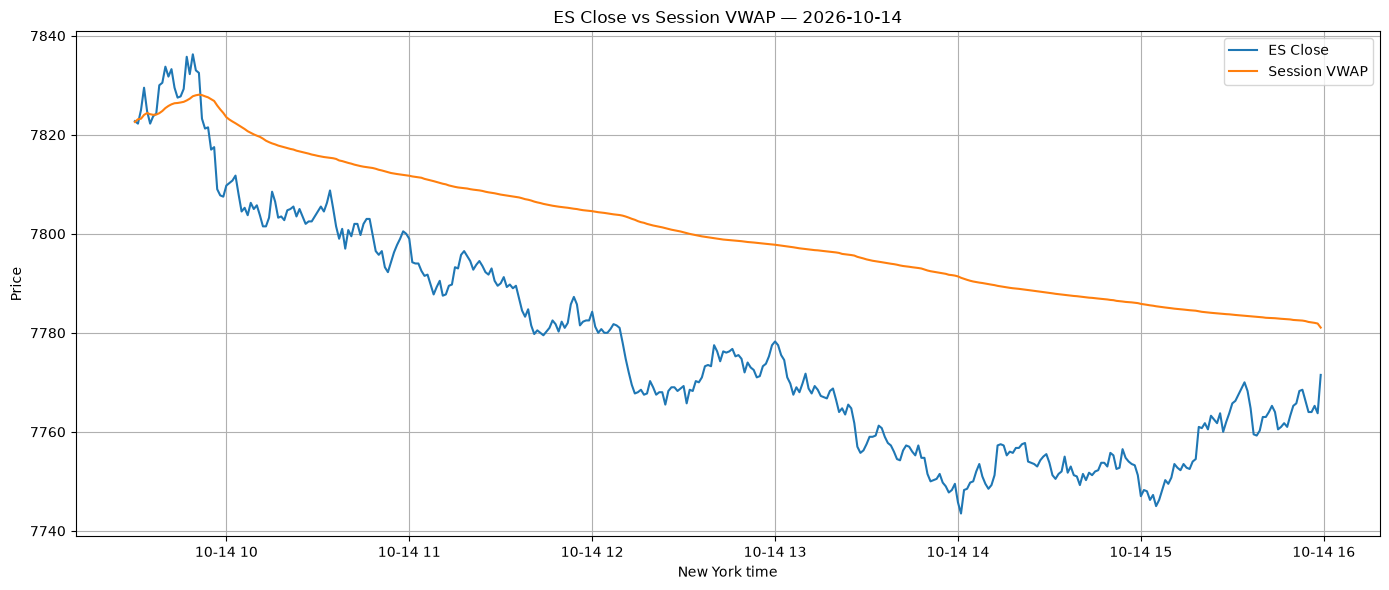

In [9]:
import matplotlib.pyplot as plt

latest_session = es_rth["sessions"].iloc[-1]
day = es_rth[es_rth["sessions"] == latest_session]

plt.figure(figsize=(14, 6))
plt.plot(day.index, day["close"], label="ES Close")
plt.plot(day.index, day["vwap"], label="Session VWAP")

plt.title(f"ES Close vs Session VWAP — {latest_session}")
plt.xlabel("New York time")
plt.ylabel("Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [10]:
bands = ind.calculate_vwap_bands()
bands.head()

,vwap,upper_1,lower_1,upper_2,lower_2,upper_3,lower_3
Datetime,,,,,,,
2026-10-08 09:30:00-04:00,7825.583333,7825.583333,7825.583333,7825.583333,7825.583333,7825.583333,7825.583333
2026-10-08 09:31:00-04:00,7826.333649,7827.301977,7825.365322,7828.270304,7824.396995,7829.238631,7823.428667
2026-10-08 09:32:00-04:00,7826.453341,7827.324282,7825.582400,7828.195223,7824.711459,7829.066164,7823.840517
2026-10-08 09:33:00-04:00,7826.937373,7828.152297,7825.722448,7829.367222,7824.507523,7830.582147,7823.292598
2026-10-08 09:34:00-04:00,7827.548317,7829.397164,7825.699471,7831.246010,7823.850624,7833.094856,7822.001778


In [11]:
signals = ind.get_signal()

print("Long signal bars:", signals["long"].sum())
print("Short signal bars:", signals["short"].sum())

Long signal bars: 78
Short signal bars: 80


In [12]:
print(
    "Sessions with long signals:",
    es_rth.loc[signals["long"], "sessions"].nunique()
)

print(
    "Sessions with short signals:",
    es_rth.loc[signals["short"], "sessions"].nunique()
)

Sessions with long signals: 5
Sessions with short signals: 5


In [13]:
new_session = es_rth["sessions"].ne(es_rth["sessions"].shift())

long_starts = signals["long"] & (
    ~signals["long"].shift(1, fill_value=False) | new_session
)
short_starts = signals["short"] & (
    ~signals["short"].shift(1, fill_value=False) | new_session
)

print("Long signal episodes:", long_starts.sum())
print("Short signal episodes:", short_starts.sum())

Long signal episodes: 27
Short signal episodes: 29


In [14]:
bands.columns

Index(['vwap', 'upper_1', 'lower_1', 'upper_2', 'lower_2', 'upper_3',
       'lower_3'],
      dtype='str')

In [15]:
import numpy as np

events = es_rth.loc[
    long_starts | short_starts,
    ['close', 'sessions', 'vwap']
].copy()


events['signal'] = np.where(
    long_starts.loc[events.index],
    'long',
    'short'
)

events['timestamp'] = events.index

events['upper_2'] = bands.loc[events.index, 'upper_2'].copy()
events['lower_2'] = bands.loc[events.index, 'lower_2'].copy()





In [16]:
events.head()

Price,close,sessions,vwap,signal,timestamp,upper_2,lower_2
Datetime,,,,,,,
2026-10-08 09:34:00-04:00,7831.75,2026-10-08,7827.548317,short,2026-10-08 09:34:00-04:00,7831.246010,7823.850624
2026-10-08 09:49:00-04:00,7832.50,2026-10-08,7827.114516,short,2026-10-08 09:49:00-04:00,7830.839951,7823.389081
2026-10-08 09:58:00-04:00,7834.75,2026-10-08,7828.588903,short,2026-10-08 09:58:00-04:00,7834.487548,7822.690258
2026-10-08 10:05:00-04:00,7836.00,2026-10-08,7829.167858,short,2026-10-08 10:05:00-04:00,7835.351153,7822.984563
2026-10-08 10:12:00-04:00,7839.00,2026-10-08,7830.098931,short,2026-10-08 10:12:00-04:00,7837.730398,7822.467464


In [17]:
len(events)

56

In [18]:
long_lower_2 = events[(events['signal'] == 'long') & (events['close'] < events['lower_2'])]
short_upper_2 = events[(events['signal'] == 'short') & (events['close'] > events['upper_2'])]

len(long_lower_2), len(short_upper_2)


(27, 29)

In [19]:
length_val_long = len(long_lower_2)
length_val_short = len(short_upper_2)

inv_longs = np.sum(events['signal'] == 'long') - length_val_long
inv_short = np.sum(events['signal'] == 'short') - length_val_short

total_events = len(events)

inv_longs, inv_short, total_events


(np.int64(0), np.int64(0), 56)

In [20]:
length_val_long, length_val_short

(27, 29)

In [21]:
print(f"Invalid longs: {int(inv_longs)}")
print(f"Invalid shorts: {int(inv_short)}")

events.dropna()

events.head(5)

Invalid longs: 0
Invalid shorts: 0


Price,close,sessions,vwap,signal,timestamp,upper_2,lower_2
Datetime,,,,,,,
2026-10-08 09:34:00-04:00,7831.75,2026-10-08,7827.548317,short,2026-10-08 09:34:00-04:00,7831.246010,7823.850624
2026-10-08 09:49:00-04:00,7832.50,2026-10-08,7827.114516,short,2026-10-08 09:49:00-04:00,7830.839951,7823.389081
2026-10-08 09:58:00-04:00,7834.75,2026-10-08,7828.588903,short,2026-10-08 09:58:00-04:00,7834.487548,7822.690258
2026-10-08 10:05:00-04:00,7836.00,2026-10-08,7829.167858,short,2026-10-08 10:05:00-04:00,7835.351153,7822.984563
2026-10-08 10:12:00-04:00,7839.00,2026-10-08,7830.098931,short,2026-10-08 10:12:00-04:00,7837.730398,7822.467464


In [22]:
from event_study import EventStudy
import pandas as pd
import numpy as np

study = EventStudy(es_rth)
events = study.calculate_data()

print("Total events:", len(events))
print("\nEvents by direction:")
print(events["signal"].value_counts())

horizons = (5, 15, 30)

print("\nValid observations:")
for h in horizons:
    print(f"{h} bars: {events[f'return_{h}'].notna().sum()}")

print("\nForward directional price changes:")
for h in horizons:
    col = f"return_{h}"
    valid = events[col].dropna()

    print(f"\n{h}-bar horizon")
    print("Mean:", round(valid.mean(), 4))
    print("Median:", round(valid.median(), 4))
    print("Positive outcomes (%):", round((valid > 0).mean() * 100, 2))

print("\nStatistics by signal direction:")
for h in horizons:
    col = f"return_{h}"
    print(f"\n{h}-bar horizon")

    print(
        events.groupby("signal")[col].agg(
            ["count", "mean", "median"]
        )
    )

    print(
        "Positive outcomes (%):",
        (events.assign(positive=events[col] > 0)
         .groupby("signal")["positive"].mean() * 100).round(2)
    )

print("\nFirst five events:")
print(events.head())

return_cols = [f"return_{h}" for h in horizons]
print("\nInfinite values:", np.isinf(events[return_cols]).sum().sum())

Total events: 56

Events by direction:
signal
short    29
long     27
Name: count, dtype: int64

Valid observations:
5 bars: 56
15 bars: 56
30 bars: 56

Forward directional price changes:

5-bar horizon
Mean: 0.9509
Median: 1.5
Positive outcomes (%): 62.5

15-bar horizon
Mean: 1.0089
Median: 0.0
Positive outcomes (%): 48.21

30-bar horizon
Mean: 1.7723
Median: 0.5
Positive outcomes (%): 53.57

Statistics by signal direction:

5-bar horizon
        count      mean  median
signal                         
long       27 -0.416667    1.25
short      29  2.224138    1.75
Positive outcomes (%): signal
long     59.26
short    65.52
Name: positive, dtype: float64

15-bar horizon
        count      mean  median
signal                         
long       27 -0.490741   -1.25
short      29  2.405172    0.00
Positive outcomes (%): signal
long     48.15
short    48.28
Name: positive, dtype: float64

30-bar horizon
        count      mean  median
signal                         
long       27 -1.75925

In [23]:
import importlib
import event_study

importlib.reload(event_study)

EventStudy = event_study.EventStudy
study = EventStudy(es_rth)

events = study.calculate_data()

In [24]:
print("Total events:", len(events))

print("\nEvents by direction:")
print(events["signal"].value_counts())

for h in (5, 15, 30):
    col = f"return_{h}"
    valid = events[col].dropna()

    print(f"\n{'=' * 12} {h}-bar horizon {'=' * 12}")
    print("Valid observations:", len(valid))
    print("Mean directional change:", round(valid.mean(), 4), "points")
    print("Median directional change:", round(valid.median(), 4), "points")
    print("Positive outcomes:", round((valid > 0).mean() * 100, 2), "%")

    print("\nBy signal:")
    print(
        events.groupby("signal")[col]
        .agg(["count", "mean", "median"])
        .round(4)
    )

print("\nFirst 10 events:")
display(events.head(10))

Total events: 56

Events by direction:
signal
short    29
long     27
Name: count, dtype: int64

============ 5-bar horizon ============
Valid observations: 56
Mean directional change: 0.9509 points
Median directional change: 1.5 points
Positive outcomes: 62.5 %

By signal:
        count    mean  median
signal                       
long       27 -0.4167    1.25
short      29  2.2241    1.75

============ 15-bar horizon ============
Valid observations: 56
Mean directional change: 1.0089 points
Median directional change: 0.0 points
Positive outcomes: 48.21 %

By signal:
        count    mean  median
signal                       
long       27 -0.4907   -1.25
short      29  2.4052    0.00

============ 30-bar horizon ============
Valid observations: 56
Mean directional change: 1.7723 points
Median directional change: 0.5 points
Positive outcomes: 53.57 %

By signal:
        count    mean  median
signal                       
long       27 -1.7593     0.0
short      29  5.0603     4.0

Fi

Price,close,sessions,vwap,signal,entry,timestamp,upper_2,lower_2,return_5,return_15,return_30
Datetime,,,,,,,,,,,
2026-10-08 09:34:00-04:00,7831.75,2026-10-08,7827.548317,short,7831.75,2026-10-08 09:34:00-04:00,7831.246010,7823.850624,4.00,-0.75,-2.00
2026-10-08 09:49:00-04:00,7832.50,2026-10-08,7827.114516,short,7832.75,2026-10-08 09:49:00-04:00,7830.839951,7823.389081,4.75,-1.25,-5.00
2026-10-08 09:58:00-04:00,7834.75,2026-10-08,7828.588903,short,7835.00,2026-10-08 09:58:00-04:00,7834.487548,7822.690258,3.25,-4.00,-7.75
2026-10-08 10:05:00-04:00,7836.00,2026-10-08,7829.167858,short,7836.00,2026-10-08 10:05:00-04:00,7835.351153,7822.984563,0.00,-3.25,-7.00
2026-10-08 10:12:00-04:00,7839.00,2026-10-08,7830.098931,short,7838.75,2026-10-08 10:12:00-04:00,7837.730398,7822.467464,3.00,0.50,-0.50
2026-10-08 10:22:00-04:00,7841.25,2026-10-08,7831.060543,short,7841.25,2026-10-08 10:22:00-04:00,7839.976427,7822.144659,2.75,0.00,9.25
2026-10-08 10:25:00-04:00,7841.50,2026-10-08,7831.571768,short,7841.25,2026-10-08 10:25:00-04:00,7841.248248,7821.895289,-0.25,1.50,11.50
2026-10-08 10:28:00-04:00,7842.50,2026-10-08,7831.944448,short,7842.75,2026-10-08 10:28:00-04:00,7842.049946,7821.838951,0.00,5.00,10.25
2026-10-08 12:48:00-04:00,7814.75,2026-10-08,7830.707274,long,7814.75,2026-10-08 12:48:00-04:00,7843.755047,7817.659501,-6.00,-14.50,-11.25


In [25]:
import pandas as pd
import numpy as np

for h in (5, 15, 30):
    col = f"return_{h}"

    print(f"\n{'=' * 15} {h}-bar horizon {'=' * 15}")

    for direction in ("long", "short"):
        x = events.loc[events["signal"] == direction, col].dropna()

        print(
            f"{direction:5} | "
            f"n={len(x):2} | "
            f"mean={x.mean():+.4f} | "
            f"median={x.median():+.4f} | "
            f"win rate={(x > 0).mean() * 100:.2f}%"
        )

    x = events[col].dropna()
    print(
        f"ALL   | n={len(x):2} | "
        f"mean={x.mean():+.4f} | "
        f"median={x.median():+.4f} | "
        f"win rate={(x > 0).mean() * 100:.2f}%"
    )


=============== 5-bar horizon ===============
long  | n=27 | mean=-0.4167 | median=+1.2500 | win rate=59.26%
short | n=29 | mean=+2.2241 | median=+1.7500 | win rate=65.52%
ALL   | n=56 | mean=+0.9509 | median=+1.5000 | win rate=62.50%

=============== 15-bar horizon ===============
long  | n=27 | mean=-0.4907 | median=-1.2500 | win rate=48.15%
short | n=29 | mean=+2.4052 | median=+0.0000 | win rate=48.28%
ALL   | n=56 | mean=+1.0089 | median=+0.0000 | win rate=48.21%

=============== 30-bar horizon ===============
long  | n=27 | mean=-1.7593 | median=+0.0000 | win rate=48.15%
short | n=29 | mean=+5.0603 | median=+4.0000 | win rate=58.62%
ALL   | n=56 | mean=+1.7723 | median=+0.5000 | win rate=53.57%


In [26]:
import numpy as np
import pandas as pd

df = study.df
events = study.events.copy()

for h in (5, 15, 30):
    future_close = df["close"].shift(-h).reindex(events.index)
    future_session = df["sessions"].shift(-h).reindex(events.index)

    same_session = (
        events["sessions"].eq(future_session)
        & future_close.notna()
    )

    # Distance from price to VWAP when the signal occurs
    initial_distance = (
        events["close"] - events["vwap"]
    ).abs()

    # Distance from future price to the same, fixed VWAP target
    future_distance = (
        future_close - events["vwap"]
    ).abs()

    # Positive = price moved closer to the event-time VWAP
    progress = (initial_distance - future_distance).where(same_session)

    events[f"reversion_{h}"] = progress

print("VWAP reversion progress (ES points)")
print("Positive = closer to the VWAP target at the signal")

for h in (5, 15, 30):
    col = f"reversion_{h}"

    print(f"\n--- {h} bars ---")

    for direction in ("long", "short"):
        x = events.loc[events["signal"] == direction, col].dropna()

        print(
            f"{direction:5} | n={len(x):2} | "
            f"mean={x.mean():+.4f} | "
            f"median={x.median():+.4f} | "
            f"closer to VWAP={(x > 0).mean() * 100:.2f}%"
        )

    x = events[col].dropna()
    print(
        f"ALL   | n={len(x):2} | "
        f"mean={x.mean():+.4f} | "
        f"median={x.median():+.4f} | "
        f"closer to VWAP={(x > 0).mean() * 100:.2f}%"
    )

VWAP reversion progress (ES points)
Positive = closer to the VWAP target at the signal

--- 5 bars ---
long  | n=27 | mean=-0.9033 | median=+0.7500 | closer to VWAP=55.56%
short | n=29 | mean=+1.4743 | median=+1.6651 | closer to VWAP=65.52%
ALL   | n=56 | mean=+0.3279 | median=+1.2500 | closer to VWAP=60.71%

--- 15 bars ---
long  | n=27 | mean=-1.0431 | median=-2.0000 | closer to VWAP=44.44%
short | n=29 | mean=-1.4464 | median=-1.2500 | closer to VWAP=31.03%
ALL   | n=56 | mean=-1.2520 | median=-1.3750 | closer to VWAP=37.50%

--- 30 bars ---
long  | n=27 | mean=-2.0330 | median=+0.0000 | closer to VWAP=48.15%
short | n=29 | mean=-2.2621 | median=-2.0000 | closer to VWAP=34.48%
ALL   | n=56 | mean=-2.1516 | median=-1.1250 | closer to VWAP=41.07%


In [27]:
# Inspect event counts and mean VWAP reversion by trading session

for h in (5, 15, 30):
    col = f"reversion_{h}"

    print(f"\n{'=' * 12} {h}-bar horizon {'=' * 12}")

    daily = (
        events.groupby(["sessions", "signal"])[col]
        .agg(["count", "mean", "median"])
        .round(3)
    )

    print(daily)

print("\nNumber of distinct sessions:", events["sessions"].nunique())
print("\nEvents per session:")
print(events.groupby("sessions").size())


============ 5-bar horizon ============
                   count   mean  median
sessions   signal                      
2026-10-08 long        6 -2.417  -4.250
           short       8  2.188   2.875
2026-10-09 long        3 -0.083   1.750
           short      13  1.500   1.750
2026-10-12 long        6 -1.663  -0.363
           short       2  1.583   1.583
2026-10-13 long        6  0.222   1.500
           short       2 -3.000  -3.000
2026-10-14 long        6 -0.167   1.625
           short       4  2.146   1.473

============ 15-bar horizon ============
                   count   mean  median
sessions   signal                      
2026-10-08 long        6 -2.667  -3.250
           short       8 -0.281  -0.375
2026-10-09 long        3  0.333   1.750
           short      13  0.039  -1.250
2026-10-12 long        6 -2.125  -2.500
           short       2 -3.161  -3.161
2026-10-13 long        6 -0.236   0.250
           short       2 -3.500  -3.500
2026-10-14 long        6  0.167   0.2

In [28]:
from event_study import EventStudy

es = EventStudy(es_rth)
study = es.calculate_data()

study.head(10)



Price,close,sessions,vwap,signal,entry,timestamp,upper_2,lower_2,return_5,return_15,return_30
Datetime,,,,,,,,,,,
2026-10-08 09:34:00-04:00,7831.75,2026-10-08,7827.548317,short,7831.75,2026-10-08 09:34:00-04:00,7831.246010,7823.850624,4.00,-0.75,-2.00
2026-10-08 09:49:00-04:00,7832.50,2026-10-08,7827.114516,short,7832.75,2026-10-08 09:49:00-04:00,7830.839951,7823.389081,4.75,-1.25,-5.00
2026-10-08 09:58:00-04:00,7834.75,2026-10-08,7828.588903,short,7835.00,2026-10-08 09:58:00-04:00,7834.487548,7822.690258,3.25,-4.00,-7.75
2026-10-08 10:05:00-04:00,7836.00,2026-10-08,7829.167858,short,7836.00,2026-10-08 10:05:00-04:00,7835.351153,7822.984563,0.00,-3.25,-7.00
2026-10-08 10:12:00-04:00,7839.00,2026-10-08,7830.098931,short,7838.75,2026-10-08 10:12:00-04:00,7837.730398,7822.467464,3.00,0.50,-0.50
2026-10-08 10:22:00-04:00,7841.25,2026-10-08,7831.060543,short,7841.25,2026-10-08 10:22:00-04:00,7839.976427,7822.144659,2.75,0.00,9.25
2026-10-08 10:25:00-04:00,7841.50,2026-10-08,7831.571768,short,7841.25,2026-10-08 10:25:00-04:00,7841.248248,7821.895289,-0.25,1.50,11.50
2026-10-08 10:28:00-04:00,7842.50,2026-10-08,7831.944448,short,7842.75,2026-10-08 10:28:00-04:00,7842.049946,7821.838951,0.00,5.00,10.25
2026-10-08 12:48:00-04:00,7814.75,2026-10-08,7830.707274,long,7814.75,2026-10-08 12:48:00-04:00,7843.755047,7817.659501,-6.00,-14.50,-11.25
